# Expérimentations et comparaison quantitative

**Projet :** BrainScanAI - détection semi-supervisée de tumeurs cérébrales  
**Étape :** 4 - Appliquez une méthode semi-supervisée  
**Auteur :** Kilian Lefevre

---

## Objectif du notebook

Le notebook `03.02` compare un CNN entraîné sur les labels forts seuls (A) à un CNN entraîné sur les labels faibles puis sur les labels forts (C), avec une seule graine et des réglages fixés d'avance. Ce notebook répond aux questions suivantes :

- Les choix d'architecture et de réglages du notebook `03.02` sont-ils justifiés ? On teste **deux variantes** : un réseau dont seule la couche de classification s'entraîne, et une phase sur les labels faibles plus courte.
- L'écart entre A et C résiste-t-il à un changement de graine ? On répète chaque entraînement sur **plusieurs graines** et on compare A et C **graine par graine**.

**Prérequis :** le manifeste dédupliqué, le découpage et les labels faibles (`data/interim/manifest.csv`, `data/processed/split.csv` et `weak_labels.csv`), et le notebook `03.02` pour le protocole.

## Les variantes

| Variante | Couches entraînées | Époques sur les labels faibles | Graines |
|---|---|---|---|
| **référence** (celle du notebook `03.02`) | `layer4` et couche de classification | 10 | 5 |
| **tête seule** | couche de classification seule | 10 | 3 |
| **labels faibles courts** | `layer4` et couche de classification | 3 | 3 |

- *Tête seule* teste si dégeler `layer4` est utile avec si peu d'images annotées.
- *Labels faibles courts* teste si une phase plus courte limite la mémorisation des labels faibles, observée au notebook `03.02` (la perte de validation monte pendant cette phase).

Dans les trois cas, les couches de normalisation par lot restent en mode entraînement, comme dans le notebook `03.02`. Tous les autres réglages sont ceux du notebook `03.02` et ne changent pas.

**Choix de la variante.** La variante retenue est celle dont le modèle C a le **meilleur rappel de validation moyen** (puis le meilleur F1 macro de validation). Les mesures de test sont rapportées pour toutes les variantes, mais ne servent pas à choisir.

## 1. Chargement

On charge le manifeste, le découpage et les labels faibles, comme dans le notebook `03.02`.

In [1]:
from copy import deepcopy
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from brain_mri.config import (
    FIGURES_DIR,
    INTERIM_DATA_DIR,
    PROCESSED_DATA_DIR,
    set_seed,
)
from brain_mri.dataset import read_manifest, read_split
from brain_mri.features import MODEL_NAME, select_device
from brain_mri.modeling.train import (
    DECISION_THRESHOLD,
    LEARNING_RATE,
    MAX_EPOCHS,
    PATIENCE,
    TRAIN_BATCH_SIZE,
    classification_scores,
    create_model,
    fit,
    make_loader,
    predict,
)
from brain_mri.modeling.unsupervised import CLASS_CODES, encode_labels
from utils.mlflow_utils import (
    log_dataset,
    log_metrics,
    log_params,
    setup_mlflow,
    start_run,
)

pd.set_option("display.max_colwidth", 100)
plt.style.use("seaborn-v0_8-whitegrid")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

NOTEBOOK = "03.03-kl-semi-supervised-experiments"
MANIFEST_PATH = INTERIM_DATA_DIR / "manifest.csv"

print(f"Suivi MLflow : {setup_mlflow()}")
DEVICE = select_device()
print(f"Calcul sur {DEVICE}")

Suivi MLflow : sqlite:///<PROJECT_ROOT>/mlflow.db
Calcul sur mps


In [2]:
manifest = read_manifest(MANIFEST_PATH)
split = read_split(PROCESSED_DATA_DIR / "split.csv")
assert (split["image_id"] == manifest["image_id"]).all()
manifest["split"] = split["split"].to_numpy()

weak_table = pd.read_csv(
    PROCESSED_DATA_DIR / "weak_labels.csv", dtype={"image_id": str}
)
strong_label = encode_labels(manifest["label"])
is_labeled = manifest["is_labeled"].to_numpy()
weak_codes = weak_table.set_index("image_id")["weak_label"].map(CLASS_CODES)
weak_label = manifest["image_id"].map(weak_codes).to_numpy(dtype=float)

split_values = manifest["split"].to_numpy()
indices = {
    "strong": np.flatnonzero((split_values == "train") & is_labeled),
    "weak": np.flatnonzero((split_values == "train") & ~is_labeled),
    "validation": np.flatnonzero(split_values == "validation"),
    "test": np.flatnonzero(split_values == "test"),
}
print({name: len(positions) for name, positions in indices.items()})

all_positions = np.concatenate(list(indices.values()))
assert len(all_positions) == len(set(all_positions)), "jeux non disjoints"

{'strong': 68, 'weak': 1194, 'validation': 14, 'test': 15}


## 2. Les entraînements

Pour chaque variante et chaque graine, on entraîne les trois modèles du notebook `03.02` :

- **A** sur les labels forts seuls, avec arrêt anticipé ;
- **B** sur les labels faibles seuls, pendant le nombre d'époques de la variante ;
- **C**, qui poursuit B sur les labels forts, avec le même arrêt anticipé que A.

Les modèles A et B partent de la même initialisation de la couche de classification. La graine de la variante *référence* égale à 42 reproduit donc le notebook `03.02`. Chaque entraînement est un **run MLflow** : réglages, jeux, métriques de chaque époque et métriques finales. Les modèles eux-mêmes ne sont pas enregistrés.

In [3]:
VARIANTS = {
    "référence": {
        "train_layer4": True,
        "weak_epochs": 10,
        "seeds": range(42, 47),
    },
    "tête seule": {
        "train_layer4": False,
        "weak_epochs": 10,
        "seeds": range(42, 45),
    },
    "labels faibles courts": {
        "train_layer4": True,
        "weak_epochs": 3,
        "seeds": range(42, 45),
    },
}
CONDITIONS = {
    "A": "supervisé (labels forts)",
    "B": "faible (labels faibles)",
    "C": "semi-supervisé (faibles puis forts)",
}


def loader(name, labels, training, balanced=False, seed=0):
    """Lots d'un jeu de `indices`, avec ses classes (`labels`)."""
    positions = indices[name]
    return make_loader(
        manifest["filepath"].iloc[positions].tolist(),
        labels[positions].astype(int),
        training,
        balanced,
        seed,
    )


VALIDATION_LOADER = loader("validation", strong_label, training=False)
TEST_LOADER = loader("test", strong_label, training=False)


def make_model(seed, train_layer4):
    """ResNet50 du notebook `03.02`, avec `layer4` gelée si besoin."""
    model = create_model(seed, DEVICE)
    if not train_layer4:
        for parameter in model.layer4.parameters():
            parameter.requires_grad = False
    return model


def evaluate(model):
    """Métriques et scores de validation et de test d'un modèle entraîné."""
    validation_labels, validation_scores, _ = predict(
        model, VALIDATION_LOADER, DEVICE
    )
    test_labels, test_scores, _ = predict(model, TEST_LOADER, DEVICE)
    return {
        "validation": classification_scores(
            validation_labels, validation_scores
        ),
        "test": classification_scores(test_labels, test_scores),
        "test_labels": test_labels.astype(int),
        "test_scores": test_scores,
    }


def train_seed(train_layer4, weak_epochs, seed):
    """Entraîne A, B et C pour une graine ; renvoie historiques et modèles."""
    set_seed(seed)
    model_a = make_model(seed, train_layer4)
    history_a, best_a = fit(
        model_a,
        loader("strong", strong_label, True, False, seed),
        VALIDATION_LOADER,
        MAX_EPOCHS,
        DEVICE,
        PATIENCE,
    )
    set_seed(seed)
    model_b = make_model(seed, train_layer4)
    history_b, _ = fit(
        model_b,
        loader("weak", weak_label, True, True, seed),
        VALIDATION_LOADER,
        weak_epochs,
        DEVICE,
    )
    set_seed(seed)
    model_c = deepcopy(model_b)
    history_c, best_c = fit(
        model_c,
        loader("strong", strong_label, True, False, seed),
        VALIDATION_LOADER,
        MAX_EPOCHS,
        DEVICE,
        PATIENCE,
    )
    return {
        "A": (model_a, [history_a], best_a),
        "B": (model_b, [history_b], None),
        "C": (model_c, [history_b, history_c], best_c),
    }

In [4]:
def dataset_table(name):
    """Table d'un jeu pour MLflow : `image_id` et label (fort ou faible)."""
    rows = manifest.iloc[indices[name]]
    if name == "weak":
        classes = np.where(weak_label[indices[name]] == 1, "cancer", "normal")
        return rows[["image_id"]].assign(weak_label=classes)
    return rows[["image_id", "subset", "label"]]


TRAINING_SETS = {"A": ("strong",), "B": ("weak",), "C": ("weak", "strong")}


def log_run(variant, settings, condition, seed, histories, best_epoch, scores):
    """Enregistre le run d'un modèle (réglages, jeux, courbes, métriques)."""
    with start_run(
        f"{variant}-{condition}-seed{seed}",
        phase="semi-supervised",
        notebook=NOTEBOOK,
        manifest_path=MANIFEST_PATH,
        seed=seed,
        description=(
            f"Variante {variant}, modèle {condition} - "
            f"{CONDITIONS[condition]}, graine {seed}"
        ),
    ):
        log_params(
            {
                "variant": variant,
                "condition": condition,
                "backbone": MODEL_NAME,
                "trained_layers": (
                    "layer4 + couche finale"
                    if settings["train_layer4"]
                    else "couche finale"
                ),
                "learning_rate": LEARNING_RATE,
                "batch_size": TRAIN_BATCH_SIZE,
                "weak_epochs": settings["weak_epochs"],
                "max_epochs": MAX_EPOCHS,
                "patience": PATIENCE,
                "decision_threshold": DECISION_THRESHOLD,
            }
        )
        for name in (*TRAINING_SETS[condition], "validation", "test"):
            training = name in ("strong", "weak")
            log_dataset(
                dataset_table(name),
                name=f"train-{name}" if training else name,
                context="training" if training else name,
                source="data/interim/manifest.csv",
                targets="weak_label" if name == "weak" else "label",
            )
        step = 0
        for history in histories:
            for _, row in history.iterrows():
                step += 1
                log_metrics(
                    {
                        key: row[key]
                        for key in history.columns
                        if key != "epoch"
                    },
                    step=step,
                )
        log_metrics(
            {
                **{f"val_{k}": v for k, v in scores["validation"].items()},
                **{f"test_{k}": v for k, v in scores["test"].items()},
                "best_epoch": best_epoch if best_epoch is not None else 0,
                "epochs_run": sum(len(history) for history in histories),
            }
        )

In [5]:
rows, test_scores = [], {}
for variant, settings in VARIANTS.items():
    for seed in settings["seeds"]:
        start = time.perf_counter()
        trained = train_seed(
            settings["train_layer4"], settings["weak_epochs"], seed
        )
        for condition, (model, histories, best_epoch) in trained.items():
            result = evaluate(model)
            log_run(
                variant,
                settings,
                condition,
                seed,
                histories,
                best_epoch,
                result,
            )
            rows.append(
                {
                    "variante": variant,
                    "modèle": condition,
                    "graine": seed,
                    "époques": sum(len(history) for history in histories),
                    **{f"val_{k}": v for k, v in result["validation"].items()},
                    **{f"test_{k}": v for k, v in result["test"].items()},
                }
            )
            test_scores[variant, condition, seed] = (
                result["test_labels"],
                result["test_scores"],
            )
        print(f"{variant}, graine {seed} : {time.perf_counter() - start:.0f} s")
results = pd.DataFrame(rows)

référence, graine 42 : 128 s
référence, graine 43 : 134 s
référence, graine 44 : 131 s
référence, graine 45 : 128 s
référence, graine 46 : 124 s
tête seule, graine 42 : 108 s
tête seule, graine 43 : 98 s
tête seule, graine 44 : 99 s
labels faibles courts, graine 42 : 50 s
labels faibles courts, graine 43 : 53 s
labels faibles courts, graine 44 : 51 s


## 3. Résultats par variante

Chaque cellule du tableau donne la **moyenne et l'écart-type** sur les graines de la variante. Les mesures de validation servent à choisir la variante ; celles de test sont rapportées pour toutes, sans servir au choix.

In [6]:
METRICS = {
    "recall": "Rappel (cancer)",
    "precision": "Précision (cancer)",
    "f1_macro": "F1 macro",
    "accuracy": "Exactitude",
}


def summary(part):
    """Moyenne ± écart-type de chaque métrique, par variante et par modèle."""
    table = {}
    for (variant, model), group in results.groupby(
        ["variante", "modèle"], sort=False
    ):
        table[variant, model] = {
            label: f"{group[f'{part}_{key}'].mean():.3f} ± {group[f'{part}_{key}'].std():.3f}"
            for key, label in METRICS.items()
        }
    return pd.DataFrame(table).T.rename_axis(["variante", "modèle"])


print("Validation (14 images)")
display(summary("val"))
print("Test (15 images)")
display(summary("test"))

Validation (14 images)


Rappel (cancer) Précision (cancer)  \
variante              modèle                                      
référence             A        1.000 ± 0.000      0.817 ± 0.053   
                      B        0.543 ± 0.064      0.790 ± 0.022   
                      C        0.829 ± 0.064      0.807 ± 0.070   
tête seule            A        0.952 ± 0.082      0.704 ± 0.105   
                      B        0.619 ± 0.082      0.811 ± 0.019   
                      C        0.714 ± 0.000      0.833 ± 0.000   
labels faibles courts A        1.000 ± 0.000      0.810 ± 0.056   
                      B        0.667 ± 0.082      0.822 ± 0.019   
                      C        0.857 ± 0.000      0.786 ± 0.062   

                                   F1 macro     Exactitude  
variante              modèle                                
référence             A       0.884 ± 0.041  0.886 ± 0.039  
                      B       0.692 ± 0.037  0.700 ± 0.032  
                      C       0.814 ± 0.064  0.814 ± 0.064  
tête seule            A       0.743 ± 0.137  0.762 ± 0.109  
                      B       0.734 ± 0.044  0.738 ± 0.041  
                      C       0.785 ± 0.000  0.786 ± 0.000  
labels faibles courts A       0.879 ± 0.043  0.881 ± 0.041  
                      B       0.759 ± 0.044  0.762 ± 0.041  
                      C       0.809 ± 0.042  0.810 ± 0.041

Test (15 images)


Rappel (cancer) Précision (cancer)  \
variante              modèle                                      
référence             A        0.825 ± 0.112      1.000 ± 0.000   
                      B        0.425 ± 0.068      1.000 ± 0.000   
                      C        0.875 ± 0.000      1.000 ± 0.000   
tête seule            A        0.875 ± 0.217      0.822 ± 0.168   
                      B        0.250 ± 0.000      1.000 ± 0.000   
                      C        0.375 ± 0.217      1.000 ± 0.000   
labels faibles courts A        0.792 ± 0.072      1.000 ± 0.000   
                      B        0.333 ± 0.072      1.000 ± 0.000   
                      C        0.833 ± 0.072      1.000 ± 0.000   

                                   F1 macro     Exactitude  
variante              modèle                                
référence             A       0.906 ± 0.060  0.907 ± 0.060  
                      B       0.674 ± 0.044  0.693 ± 0.037  
                      C       0.933 ± 0.000  0.933 ± 0.000  
tête seule            A       0.786 ± 0.081  0.800 ± 0.067  
                      B       0.550 ± 0.000  0.600 ± 0.000  
                      C       0.632 ± 0.142  0.667 ± 0.115  
labels faibles courts A       0.888 ± 0.039  0.889 ± 0.038  
                      B       0.611 ± 0.053  0.644 ± 0.038  
                      C       0.911 ± 0.039  0.911 ± 0.038

In [7]:
validation_of_c = (
    results[results["modèle"] == "C"]
    .groupby("variante", sort=False)[["val_recall", "val_f1_macro"]]
    .mean()
    .sort_values(["val_recall", "val_f1_macro"], ascending=False)
)
display(validation_of_c.round(3))
selected_variant = validation_of_c.index[0]
print(f"Variante retenue : {selected_variant}")

,val_recall,val_f1_macro
variante,,
labels faibles courts,0.857,0.809
référence,0.829,0.814
tête seule,0.714,0.785


Variante retenue : labels faibles courts


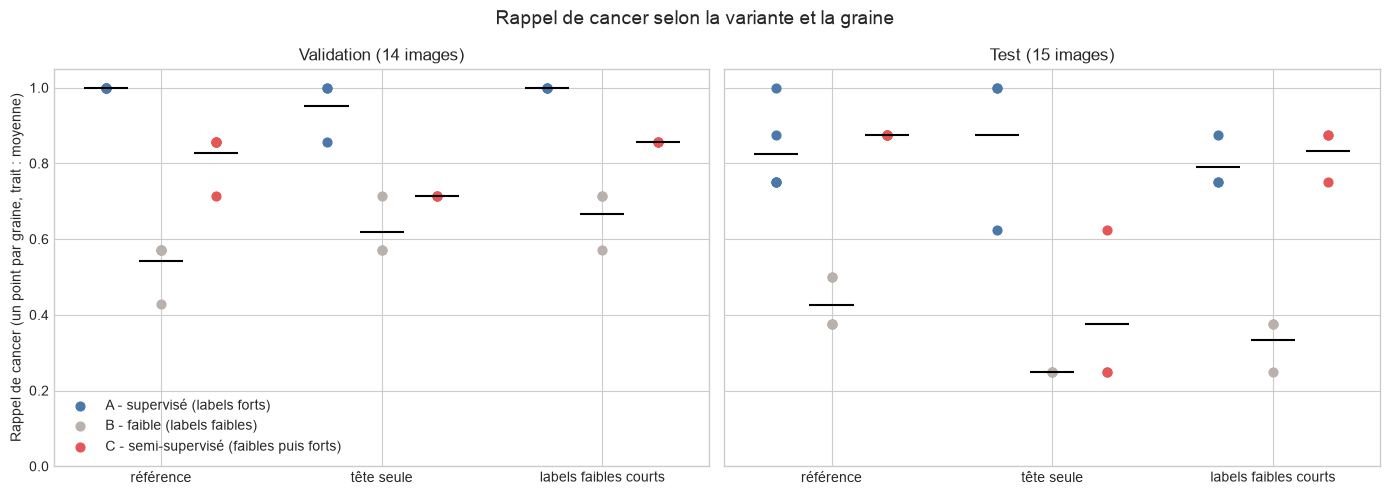

In [8]:
figure, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
colors = {"A": "#4C78A8", "B": "#BAB0AC", "C": "#E45756"}
for axis, part, title in (
    (axes[0], "val", "Validation (14 images)"),
    (axes[1], "test", "Test (15 images)"),
):
    for position, variant in enumerate(VARIANTS):
        for shift, condition in zip((-0.25, 0, 0.25), "ABC", strict=True):
            values = results[
                (results["variante"] == variant)
                & (results["modèle"] == condition)
            ][f"{part}_recall"]
            axis.scatter(
                np.full(len(values), position + shift),
                values,
                color=colors[condition],
                s=40,
                label=f"{condition} - {CONDITIONS[condition]}"
                if position == 0
                else None,
            )
            axis.hlines(
                values.mean(),
                position + shift - 0.1,
                position + shift + 0.1,
                color="black",
            )
    axis.set(
        title=title,
        xticks=range(len(VARIANTS)),
        xticklabels=list(VARIANTS),
        ylim=(0, 1.05),
    )
axes[0].set_ylabel("Rappel de cancer (un point par graine, trait : moyenne)")
axes[0].legend(loc="lower left")
figure.suptitle("Rappel de cancer selon la variante et la graine", fontsize=14)
plt.tight_layout()
figure.savefig(
    FIGURES_DIR / "experiences-rappel.png", dpi=120, bbox_inches="tight"
)
plt.show()

### Lecture des deux expérimentations

**Expérience 1 : dégeler `layer4` est utile.** Quand seule la couche de classification s'entraîne, le modèle A perd en précision (0,70 contre 0,82 sur la validation, 0,82 contre 1,00 sur le test : des fausses alertes) et en F1 macro de validation (0,74 contre 0,88). Le modèle C devient **nettement moins bon que A** : rappel de test de 0,38 contre 0,88, F1 macro de 0,63 contre 0,93. Les caractéristiques du ResNet50 pré-entraîné, figées, ne suffisent pas, et les labels faibles tirent une couche linéaire vers leur partition sans que les 68 labels forts la corrigent. Cette explication est une hypothèse, pas une mesure de ce notebook. L'entraînement de `layer4` du notebook `03.02` est donc justifié.

**Expérience 2 : raccourcir la phase sur les labels faibles change peu.** Sur 3 époques au lieu de 10, le modèle B est meilleur sur la validation (rappel de 0,67 contre 0,54, F1 macro de 0,76 contre 0,69), mais le modèle C ne change presque pas : rappel de validation de 0,86 contre 0,83, F1 macro de 0,81 des deux côtés, et sur le test un rappel de 0,83 contre 0,88. Le modèle A ne dépend pas de cette phase : ses valeurs ne diffèrent que par le nombre de graines (3 contre 5).

**Variante retenue.** Selon la règle fixée d'avance, c'est *labels faibles courts* : son rappel de validation moyen pour C est de 0,857 contre 0,829. Cet écart de 0,03 est inférieur à celui d'une image de validation (0,14 sur 7 cancers) : le choix n'est pas démontré, et le test ne le confirme pas.

**Dans tous les cas, A est meilleur que C sur la validation** (rappel de 1,00 pour la référence et les labels faibles courts). Cette validation sert à l'arrêt anticipé de A et de C.

## 4. A contre C, graine par graine

On compare, sur chaque graine, le rappel de `cancer` de C et celui de A sur les mêmes 15 images de test.

In [9]:
test_recall = results.pivot_table(
    index=["variante", "graine"], columns="modèle", values="test_recall"
)
test_f1 = results.pivot_table(
    index=["variante", "graine"], columns="modèle", values="test_f1_macro"
)
paired = pd.DataFrame(
    {
        "rappel A": test_recall["A"],
        "rappel C": test_recall["C"],
        "C moins A": test_recall["C"] - test_recall["A"],
    }
).reindex(list(VARIANTS), level=0)
display(paired.round(3))

summary_rows = []
for variant in VARIANTS:
    gap = paired.loc[variant, "C moins A"]
    f1_gap = (test_f1["C"] - test_f1["A"]).loc[variant]
    summary_rows.append(
        {
            "variante": variant,
            "graines": len(gap),
            "C meilleur": int((gap > 0).sum()),
            "égal": int((gap == 0).sum()),
            "C moins bon": int((gap < 0).sum()),
            "rappel, C moins A (moyenne)": gap.mean(),
            "F1 macro, C moins A (moyenne)": f1_gap.mean(),
        }
    )
display(pd.DataFrame(summary_rows).set_index("variante").round(3))

rappel A  rappel C  C moins A
variante              graine                               
référence             42         0.750     0.875      0.125
                      43         0.750     0.875      0.125
                      44         0.875     0.875      0.000
                      45         1.000     0.875     -0.125
                      46         0.750     0.875      0.125
tête seule            42         0.625     0.625      0.000
                      43         1.000     0.250     -0.750
                      44         1.000     0.250     -0.750
labels faibles courts 42         0.750     0.875      0.125
                      43         0.750     0.750      0.000
                      44         0.875     0.875      0.000

,graines,C meilleur,égal,C moins bon,"rappel, C moins A (moyenne)","F1 macro, C moins A (moyenne)"
variante,,,,,,
référence,5,3,1,1,0.050,0.027
tête seule,3,0,1,2,-0.500,-0.154
labels faibles courts,3,1,2,0,0.042,0.022


- **Référence.** Le rappel de test de C est de 0,875 à chaque graine, alors que celui de A varie de 0,75 à 1,00. C fait mieux que A sur 3 graines sur 5, autant sur 1 et moins bien sur 1.
- **Labels faibles courts.** C fait mieux que A sur 1 graine sur 3 et autant sur les 2 autres.
- **Tête seule.** C ne fait jamais mieux que A, et fait nettement moins bien sur 2 graines sur 3.

## 5. Observations et limites

### Observations

- **Dégeler `layer4` est justifié.** Avec la seule couche de classification, A fait des fausses alertes (précision de test de 0,82 contre 1,00) et C devient nettement moins bon que A. Les caractéristiques d'ImageNet figées ne suffisent pas, et les labels faibles tirent alors une couche linéaire vers leur partition sans que les 68 labels forts la corrigent (hypothèse, non mesurée ici).
- **Raccourcir la phase sur les labels faibles n'est ni démontré utile ni nuisible.** B s'améliore sur la validation, mais C ne change presque pas. La variante est retenue par la règle fixée d'avance, d'un écart inférieur à une image de validation.
- **A contre C.** Sur la référence, C fait mieux que A ou autant sur 4 graines sur 5, avec un rappel de test constant (0,875), dans le sens attendu d'une approche semi-supervisée. L'écart est d'une image.

### Limites

- **Test de 15 images** (8 `cancer`, 7 `normal`) : un cancer raté représente 12,5 points de rappel. Un écart d'une image entre deux modèles n'est pas significatif : on ne peut pas conclure avec si peu de données.
- **Peu de graines** : 5 pour la référence, 3 pour les autres variantes.
- **Choix sur 14 images de validation.** L'écart qui désigne la variante retenue est inférieur à une image.
- **Peu de variantes.** Deux changements seulement ont été testés (couches entraînées, durée de la phase faible).
- **Normalisation par lot** : ses statistiques continuent de s'adapter aux IRM, même quand `layer4` est gelée.
- **Labels faibles de qualité limitée** (notebook `03.01`) : leur effet est le même dans toutes les variantes.